# Detección de Anomalías de Red con Random Forest

La detección de anomalías identifica puntos de datos que se desvían significativamente del comportamiento habitual. En ciberseguridad, estas desviaciones suelen indicar actividades maliciosas, intrusiones en la red o violaciones de seguridad. Los modelos **Random Forest** (Bosques Aleatorios), al ser ensamblajes de árboles de decisión, resultan idóneos para manejar datos complejos y de alta dimensionalidad en este tipo de escenarios.

## 1. Algoritmo Random Forest

Un Random Forest es un algoritmo de Machine Learning basado en _ensemble learning_ (aprendizaje por conjunto) que construye múltiples árboles de decisión durante el entrenamiento y combina sus predicciones:

- **Clasificación:** Cada árbol emite un voto por una clase. La clase con la mayoría de votos se selecciona como la predicción final.
    
- **Regresión:** La predicción final es la media aritmética de las salidas de los árboles individuales.
    

Al promediar o combinar los resultados de múltiples árboles, el modelo reduce la varianza y el sobreajuste (_overfitting_) en comparación con un único árbol de decisión.

### Conceptos Clave de Construcción

1. **Bootstrapping (Bagging):** Se crean múltiples subconjuntos del dataset de entrenamiento mediante muestreo aleatorio con reemplazo. Cada subconjunto entrena un árbol de decisión independiente.
    
2. **Construcción de Árboles con Subconjuntos de Características:** En cada división (_split_) de un nodo, el árbol solo considera un subconjunto aleatorio de características. Esto garantiza diversidad entre los árboles y reduce la correlación entre ellos.
    
3. **Votación Mayoritaria:** Tras entrenar todos los árboles, la clasificación final se determina por consenso mayoritario.
    

### Aplicación a la Detección de Anomalías

Para detectar anomalías, el modelo se entrena prioritariamente con datos que representan tráfico o comportamiento normal. Cuando se evalúan nuevos eventos:

- Los eventos que se ajustan a las reglas aprendidas se clasifican como normales.
    
- Las observaciones que producen bajas probabilidades de confianza o patrones no reconocidos son etiquetadas como posibles anomalías o tráfico sospechoso.
    

## 2. El Dataset NSL-KDD

El dataset **NSL-KDD** es una versión depurada del clásico dataset _KDD Cup 1999_. Resuelve deficiencias clave de este último, como la presencia masiva de registros duplicados o redundantes y el sesgo extremo en la distribución de clases. Es un benchmark estándar en la investigación de Sistemas de Detección de Intrusiones (IDS).

Ventajas de NSL-KDD:

- Permite tanto **clasificación binaria** (Tráfico Normal vs. Anómalo/Ataque) como **clasificación multiclase** (DoS, Probe, R2L, U2R).
    
- Mantiene una proporción balanceada de registros entre los conjuntos de entrenamiento y prueba.
    

## 3. Descarga y Carga de Datos en Python

### Descarga del Dataset

El dataset se distribuye comprimido en formato `.zip`. Utilizando la librería `requests` e `io`, se descarga y descomprime directamente en memoria:

In [1]:
import requests, zipfile, io

# URL del dataset NSL-KDD comprimido
url = "https://cdn.services-k8s.prod.aws.htb.systems/content/modules/292/KDD_dataset.zip"

# Descargar el archivo zip y extraer su contenido localmente
response = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(response.content))
z.extractall('.')  # Extrae los archivos en el directorio actual

### Importación de Librerías

In [2]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, confusion_matrix, classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

### Mapeo de Columnas y Estructuración

Dado que el archivo `KDD+.txt` no contiene encabezados, es necesario definir explícitamente el nombre de las $43$ características y etiquetas que componen el dataset:

In [3]:
# Ruta del archivo extraído
file_path = r'KDD+.txt'

# Definición de nombres de columnas del dataset NSL-KDD
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 
    'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'attack', 'level'
]

# Cargar el dataset en un DataFrame de Pandas
df = pd.read_csv(file_path, names=columns)

# Inspeccionar las primeras filas
print(df.head())

   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_same_srv_rate  \
0               0       0    0  ...                    0.17   
1               0       0    0  ...                    0.00   
2               0       0    0  ...                    0.10   
3               0       0    0  ...                    1.00   
4               0       0    0  ...                    1.00   

   dst_host_diff_srv_rate  dst_host_same_src_port_rate  \
0                    0.03                         0.17   
1                    0.60                         0.88   
2             

Las columnas incluyen:

- **Métricas generales de red:** `duration`, `src_bytes`, `dst_bytes`.
    
- **Variables categóricas:** `protocol_type` (tcp, udp, icmp), `service` (http, ftp, etc.), `flag` (SF, REJ, etc.).
    
- **Estadísticas de tráfico e inicio de sesión:** `num_failed_logins`, `logged_in`, `count`, `srv_count`.
    
- **Etiquetas de salida:** `attack` (tipo específico de ataque o 'normal') y `level` (nivel de dificultad de detección).

# Preprocesamiento y División del Dataset NSL-KDD

El preprocesamiento del dataset NSL-KDD prepara los registros de tráfico de red para entrenar modelos de detección de anomalías basados en **Random Forest**. Los objetivos principales consisten en definir las variables objetivo (_targets_), codificar las variables categóricas a formatos legibles numéricamente y seleccionar las características cuantitativas relevantes.

## 1. Definición de Variables Objetivo (_Targets_)

### Clasificación Binaria

Para identificar de forma rápida si una conexión es legítima o maliciosa, se genera la columna `attack_flag`:

- `0`: Tráfico normal (`normal`).
    
- `1`: Cualquier tipo de ataque.

In [4]:
# Mapeo binario: 0 para tráfico normal, 1 para ataques
df['attack_flag'] = df['attack'].apply(lambda a: 0 if a == 'normal' else 1)

### Clasificación Multiclase

Para distinguir la naturaleza específica del ataque, se mapean las amenazas en cuatro grandes categorías tácticas:

1. **DoS (Denegación de Servicio):** Inundación de tráfico o consumo de recursos (ej. _neptune_, _smurf_, _pod_).
    
2. **Probe (Reconocimiento/Escaneo):** Escaneo de puertos y búsqueda de vulnerabilidades (ej. _nmap_, _ipsweep_, _satan_).
    
3. **Privilege Escalation / U2R:** Intentos de obtener privilegios de administración (ej. _buffer_overflow_, _rootkit_).
    
4. **Access / R2L:** Accesos no autorizados desde ubicaciones remotas (ej. _guess_passwd_, _ftp_write_).
    

In [6]:
# Listas de clasificación por categoría de ataque
dos_attacks = ['apache2', 'back', 'land', 'neptune', 'mailbomb', 'pod', 
               'processtable', 'smurf', 'teardrop', 'udpstorm', 'worm']
probe_attacks = ['ipsweep', 'mscan', 'nmap', 'portsweep', 'saint', 'satan']
privilege_attacks = ['buffer_overflow', 'loadmdoule', 'perl', 'ps', 
                     'rootkit', 'sqlattack', 'xterm']
access_attacks = ['ftp_write', 'guess_passwd', 'http_tunnel', 'imap', 
                  'multihop', 'named', 'phf', 'sendmail', 'snmpgetattack', 
                  'snmpguess', 'spy', 'warezclient', 'warezmaster', 
                  'xclock', 'xsnoop']

def map_attack(attack):
    if attack in dos_attacks:
        return 1
    elif attack in probe_attacks:
        return 2
    elif attack in privilege_attacks:
        return 3
    elif attack in access_attacks:
        return 4
    else:
        return 0  # Tráfico normal

# Asignar la categoría numérica multiclase
df['attack_map'] = df['attack'].apply(map_attack)

## 2. Codificación de Variables Categóricas (_One-Hot Encoding_)

Los algoritmos de Machine Learning requieren entradas estrictamente numéricas. Las variables categóricas como `protocol_type` (tcp, udp, icmp) y `service` (http, ftp, smtp, etc.) se transforman mediante **One-Hot Encoding** utilizando `pd.get_dummies()`. Esto crea columnas binarias indicadoras ($0$ o $1$) evitando relaciones ordinales falsas.

In [7]:
# Codificación One-Hot para atributos categóricos
features_to_encode = ['protocol_type', 'service']
encoded = pd.get_dummies(df[features_to_encode])

## 3. Selección de Características Numéricas

Se seleccionan las métricas numéricas que describen las propiedades estadísticas y de volumen del tráfico de red:

In [8]:
# Características numéricas del dataset
numeric_features = [
    'duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'urgent', 'hot', 
    'num_failed_logins', 'num_compromised', 'root_shell', 'su_attempted', 
    'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 
    'num_outbound_cmds', 'count', 'srv_count', 'serror_rate', 
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 
    'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 
    'dst_host_srv_rerror_rate'
]

## 4. Ensamblado del Conjunto de Datos

Se combinan las columnas generadas por la codificación One-Hot con las características numéricas seleccionadas en una única estructura llamada `train_set`.

In [10]:
# Unir características categóricas codificadas con las cuantitativas
train_set = encoded.join(df[numeric_features])

# Definir la variable objetivo multiclase
multi_y = df['attack_map']

## 5. División del Dataset (_Train / Validation / Test_)

Para evitar el sobreajuste y garantizar una evaluación imparcial, los datos se dividen en tres subconjuntos independientes:

1. **Entrenamiento (`multi_train_X`, `multi_train_y`):** Utilizado para ajustar los árboles del Random Forest.
    
2. **Validación (`multi_val_X`, `multi_val_y`):** Reservado para la optimización de hiperparámetros.
    
3. **Prueba (`test_X`, `test_y`):** Reservado exclusivamente para la evaluación final del modelo.

In [11]:
from sklearn.model_selection import train_test_split

# 1. División inicial en Entrenamiento (80%) y Prueba (20%)
train_X, test_X, train_y, test_y = train_test_split(
    train_set, multi_y, test_size=0.2, random_state=1337
)

# 2. Subdivisión del conjunto de Entrenamiento en Entrenamiento (70%) y Validación (30%)
multi_train_X, multi_val_X, multi_train_y, multi_val_y = train_test_split(
    train_X, train_y, test_size=0.3, random_state=1337
)

## Resumen de Subconjuntos Resultantes

|   |   |   |   |
|---|---|---|---|
|**Variable**|**Descripción**|**Proporción Aproximada**|**Uso**|
|`multi_train_X` / `multi_train_y`|Subset de Entrenamiento|$\approx 56\%$ del total|Ajuste de parámetros del Random Forest|
|`multi_val_X` / `multi_val_y`|Subset de Validación|$\approx 24\%$ del total|Ajuste de hiperparámetros|
|`test_X` / `test_y`|Subset de Prueba|$\approx 20\%$ del total|Evaluación final e imparcial del rendimiento|

# Entrenamiento y Evaluación: Detección de Anomalías de Red

Esta sección aborda la fase de entrenamiento y la evaluación exhaustiva de un modelo basado en **Random Forest** para la clasificación multiclase del tráfico de red utilizando el dataset NSL-KDD. El objetivo es identificar tráfico legítimo (_Normal_) frente a cuatro categorías principales de ciberataques (_DoS_, _Probe_, _Privilege_, _Access_).

## Entrenamiento del Modelo Random Forest

El entrenamiento se realiza utilizando el estimador `RandomForestClassifier` de `scikit-learn`. Se establece el parámetro `random_state=1337` para asegurar la reproducibilidad de los experimentos. El modelo aprende las relaciones existentes entre las características cuantitativas/codificadas (`multi_train_X`) y la etiqueta multiclase de destino (`multi_train_y`).

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Inicialización y entrenamiento del modelo Random Forest multiclase
rf_model_multi = RandomForestClassifier(random_state=1337)
rf_model_multi.fit(multi_train_X, multi_train_y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1337
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boots

## Evaluación en el Conjunto de Validación

La evaluación intermedia en el subconjunto de validación (`multi_val_X`, `multi_val_y`) permite ajustar parámetros y verificar la capacidad de generalización del modelo antes de evaluar sobre el conjunto final de prueba.

### Métricas de Rendimiento

Para problemas multiclase con clases desbalanceadas, las métricas globales se calculan mediante el promedio ponderado (`average='weighted'`), asegurando que cada categoría influya en proporción a su soporte real.

- **Accuracy**: Proporción total de observaciones correctamente clasificadas.
    
- **Precision**: Precisión ponderada de las predicciones positivas por clase.
    
- **Recall**: Tasa de detección o sensibilidad para cada tipo de tráfico.
    
- **F1-Score**: Media armónica entre precisión y recall.
    

### Código de Evaluación y Matriz de Confusión

Evaluación en el Conjunto de Validación:
Accuracy:  0.9950
Precision: 0.9949
Recall:    0.9950
F1-Score:  0.9949


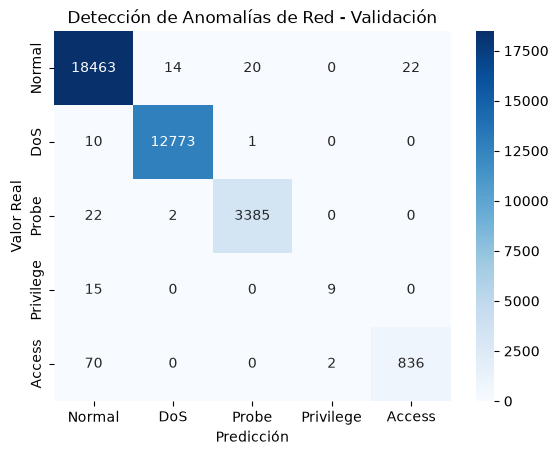

Reporte de Clasificación (Validación):
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00     18519
         DoS       1.00      1.00      1.00     12784
       Probe       0.99      0.99      0.99      3409
   Privilege       0.82      0.38      0.51        24
      Access       0.97      0.92      0.95       908

    accuracy                           1.00     35644
   macro avg       0.96      0.86      0.89     35644
weighted avg       0.99      1.00      0.99     35644



In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Predicción en el conjunto de validación
multi_predictions = rf_model_multi.predict(multi_val_X)

# Cálculo de métricas
accuracy = accuracy_score(multi_val_y, multi_predictions)
precision = precision_score(multi_val_y, multi_predictions, average='weighted')
recall = recall_score(multi_val_y, multi_predictions, average='weighted')
f1 = f1_score(multi_val_y, multi_predictions, average='weighted')

print(f"Evaluación en el Conjunto de Validación:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Generación de la Matriz de Confusión
conf_matrix = confusion_matrix(multi_val_y, multi_predictions)
class_labels = ['Normal', 'DoS', 'Probe', 'Privilege', 'Access']

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.title('Detección de Anomalías de Red - Validación')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

# Reporte detallado de clasificación
print("Reporte de Clasificación (Validación):")
print(classification_report(multi_val_y, multi_predictions, target_names=class_labels))

## Evaluación en el Conjunto de Test

Una vez validado el comportamiento del algoritmo, se evalúa sobre el conjunto de test aislado (`test_X`, `test_y`) para medir su rendimiento operativo real frente a datos no vistos.


Evaluación en el Conjunto de Test:
Accuracy:  0.9949
Precision: 0.9947
Recall:    0.9949
F1-Score:  0.9947


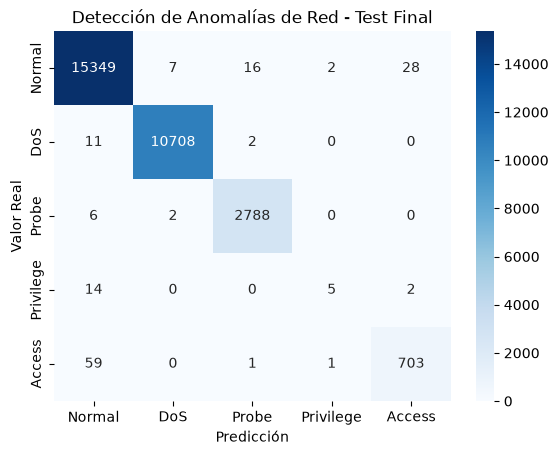

Reporte de Clasificación (Test):
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00     15402
         DoS       1.00      1.00      1.00     10721
       Probe       0.99      1.00      1.00      2796
   Privilege       0.62      0.24      0.34        21
      Access       0.96      0.92      0.94       764

    accuracy                           0.99     29704
   macro avg       0.91      0.83      0.85     29704
weighted avg       0.99      0.99      0.99     29704



In [14]:
# Predicción en el conjunto de prueba final
test_multi_predictions = rf_model_multi.predict(test_X)

# Métricas del conjunto de prueba
test_accuracy = accuracy_score(test_y, test_multi_predictions)
test_precision = precision_score(test_y, test_multi_predictions, average='weighted')
test_recall = recall_score(test_y, test_multi_predictions, average='weighted')
test_f1 = f1_score(test_y, test_multi_predictions, average='weighted')

print("\nEvaluación en el Conjunto de Test:")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")

# Matriz de Confusión para el conjunto de prueba
test_conf_matrix = confusion_matrix(test_y, test_multi_predictions)
sns.heatmap(test_conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.title('Detección de Anomalías de Red - Test Final')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

# Reporte de Clasificación Final
print("Reporte de Clasificación (Test):")
print(classification_report(test_y, test_multi_predictions, target_names=class_labels))

## Persistencia del Modelo Entrenado

Para evitar costes computacionales en ejecuciones futuras y permitir la integración del modelo en sistemas SIEM o tuberías de detección en tiempo real, el estimador se serializa en disco utilizando `joblib`.

In [15]:
import joblib

# Guardado del modelo entrenado
model_filename = 'network_anomaly_detection_model.joblib'
joblib.dump(rf_model_multi, model_filename)

print(f"Modelo guardado exitosamente en: {model_filename}")

Modelo guardado exitosamente en: network_anomaly_detection_model.joblib


# Evaluación del Modelo de Detección de Anomalías de Red en HTB

Una vez finalizado el entrenamiento del modelo **Random Forest** y guardado el archivo serializado `network_anomaly_detection_model.joblib`, se procede a la fase de evaluación en el entorno oficial de Hack The Box mediante la máquina virtual de Playground.

## Entorno de Evaluación

El sistema de validación evalúa la precisión y robustez del modelo frente a un conjunto de datos de prueba retenidos en el servidor. A diferencia del modelo de spam (que utiliza el puerto 8000), el portal y la API para el modelo de anomalías de red se ejecutan en el **puerto 8001**.

Existen dos vías para enviar el modelo serializado: mediante un script en Python desde el entorno Jupyter o a través de la interfaz web.

## Método 1: Envío del Modelo vía API (Python)

Si estás trabajando directamente dentro del Jupyter Notebook en la máquina Playground (o conectado localmente), puedes enviar el archivo `.joblib` al endpoint de la API usando la librería `requests`.

### Script de Envío

In [ ]:
import requests
import json

# URL del endpoint de evaluación para la detección de anomalías de red
url = "http://localhost:8001/api/upload"

# Ruta al archivo serializado del modelo Random Forest
model_file_path = "network_anomaly_detection_model.joblib"

# Abrir el archivo en modo binario y enviar la solicitud POST
with open(model_file_path, "rb") as model_file:
    files = {"model": model_file}
    response = requests.post(url, files=files)

# Formatear e imprimir la respuesta JSON del servidor
print(json.dumps(response.json(), indent=4))

### Detalles Técnicos del Script

1. **Puerto de Destino (`8001`):** Asegura la comunicación con el servicio específico para el IDS / Anomaly Detection.
    
2. **Carga en Modo Binario (`"rb"`):** Evita la corrupción de los datos binarios del modelo `.joblib`.
    
3. **Petición Multipart (`files`):** Envía el archivo estructurado con la clave `model` esperada por el endpoint de FastAPI/Flask.
    
4. **Respuesta y Flag:** Si el modelo supera las métricas mínimas requeridas en precisión y recall multiclase, la respuesta JSON contendrá el valor de la **flag**.
    

## Método 2: Carga Manual a través del Portal Web

Si estás ejecutando el modelo desde tu propia máquina de ataque local:

1. Conéctate a la red de laboratorios mediante la **VPN de Hack The Box**.
    
2. Despliega la máquina objetivo (_Playground VM_).
    
3. Obtén la IP asignada a la instancia (`<VM-IP>`).
    
4. Abre el navegador e ingresa a: `http://<VM-IP>:8001/`
    
5. Selecciona y sube el archivo `network_anomaly_detection_model.joblib`.
    

## Verificación de Resultados

Al recibir el archivo, la plataforma ejecutará un conjunto de pruebas automatizadas sobre el modelo subido:

- Evaluación de métricas multiclase (_Accuracy_, _F1-Score_ ponderado por categoría).
    
- Verificación de la clasificación correcta en muestras de tráfico normal, DoS, Probe, Escalada de Privilegios y Accesos No Autorizados.
    

Si el rendimiento cumple con los umbrales exigidos, el portal mostrará la flag para validar la resolución del módulo.